# HippEncoding
### Fitting a voxel-wise encoding model to the hippocampus in a naturalistic dataset


In [1]:
%config InlineBackend.figure_format = 'retina'
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
#import datalad.api as dl
import nibabel as nib
from nilearn.surface import vol_to_surf
from nilearn import plotting
import cortex
sys.path.insert(0, "/Users/ianfaul/Code/HippEncoding/hippomaps")
import hippomaps as hm
import logging
logging.basicConfig(level=logging.DEBUG)

Inkscape not found. Some tests will be skipped. If you are on a Mac or Windows machine, please specify the path to the Inkscape binary in the config file (Here: /Users/ianfaul/Library/Application Support/pycortex/options.cfg).


In [ ]:
# Clone dataset repository
study_dir = '/Users/ianfaul/Code/HippEncoding'
data_dir = '/Volumes/Aiolo/HippEncoding'  # Hard drive
if not os.path.exists(data_dir):
    print("Check that external hard drive is connected")

%cd "$data_dir"

# Clone and initialize full dataset
#dl.clone(source='https://github.com/OpenNeuroDatasets/ds003020.git', path=data_dir)
ds = dl.Dataset(data_dir)

# Get specified files
anat_path = os.path.join(data_dir, 'stimuli')
ds.get(anat_path, jobs=4)

### Load semantic model

In [ ]:
sys.path.insert(0, '/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/encoding/ridge_utils')

from SemanticModel import SemanticModel
eng1000 = SemanticModel.load("/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/em_data/english1000sm.hf5")

In [ ]:
eng1000.find_words_like_word("finger")

### Fit out-of-the-box encoding model

In [ ]:
%cd /Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/encoding
!python3 encoding.py --subject UTS03 --feature eng1000

In [ ]:
weights = np.load('/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/results/eng1000/UTS03/weights.npz')
corrs = np.load('/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/results/eng1000/UTS03/corrs.npz')

weights = weights['arr_0']
corrs = corrs['arr_0']

In [ ]:
# Plot histogram of correlations
corrs = np.load('/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/results/eng1000/UTS03/corrs.npz')

f = figure(figsize=(8,8))
ax = f.add_subplot(1,1,1)
ax.hist(corrs['arr_0'], 100) # histogram correlations with 100 bins
ax.set_xlabel("Correlation")
ax.set_ylabel("Num. voxels")

In [ ]:
# Undelay voxel weights (average across delays)
import operator
from functools import reduce
udwt = reduce(operator.add, np.split(corrs['arr_0']/4, 4))

corrsort = np.argsort(corrs['arr_0'])[::-1]
# Define function that will print best words for a voxel
import pprint

def print_voxel_words(voxnum):
    # find_words_like_vec returns 10 words most correlated with the given vector, and the correlations
    voxwords = eng1000.find_words_like_vec(udwt[:,voxnum])
    print ("Best words for voxel %d (correlation %0.3f):" % (voxnum, corrs['arr_0'][voxnum]))
    pprint.pprint(voxwords)

In [ ]:
print_voxel_words(corrsort[0]) # best voxel
print_voxel_words(corrsort[5]) # 15th best voxel  

selvoxels = [20710, 27627, 24344, 34808, 22423, 25397]

f = figure(figsize=(15, 5))
ax = f.add_subplot(1,1,1)
for ii,vi in enumerate(selvoxels):
    ax.plot(zRresp[:500, vi] - 5 * ii)
ax.set_xlim(0, 500)
ax.set_yticks([])
ax.set_xticks(range(0, 500, 50))
ax.set_xlabel("Time (fMRI volumes)")
ax.set_ylabel("Voxel responses")
ax.grid()

### Fit Whisper model

In [ ]:
# Convert textgrid files into JSONs for Whisper

textgrid_dir = "/Volumes/Aiolo/deep-fMRI-dataset/derivatives/TextGrids"
!python3 deep-fMRI-dataset/encoding/convert_textgrid_to_whisperx.py "{textgrid_dir}" --o "{textgrid_dir}"

In [ ]:
# Write stories.txt file

cache_dir = '/Volumes/Aiolo/HuggingFace/hub'
story_path = Path('/Volumes/Aiolo/deep-fMRI-dataset/stimuli')

file_names = [f.name for f in Path(story_path).iterdir() if f.is_file()]
file_names = [file[:-4] for file in file_names]
file_names.remove("auditory_localizer")

# Write to .txt file
with open("stories.txt", "a", encoding="utf-8") as file:
    for name in file_names:
        file.write(f"{name}\n")

Whisper embedding

In [ ]:
cache_dir = '/lustre/project/bdeen/HippEncoding/HuggingFace/hub'
story_path = Path('/lustre/project/bdeen/HippEncoding/stimuli')
file_names = [f.name for f in Path(story_path).iterdir() if f.is_file()]
file_names = [file[:-4] for file in file_names]
file_names.remove("auditory_localizer")

for file in file_names:
    !/lustre/project/bdeen/HippEncoding/venv/bin/python narrative-enc/code/whisper.py -m whisper-large -n $file --cache-dir $cache_dir

Layer selection

In [ ]:
%cd /Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/encoding

from select_layer import select_optimal_decoder_layer 
from encoding_utils import get_story_split

subjects = ["UTS01", "UTS02", "UTS03"]
sessions = [1, 2, 3, 4, 5]
modelname = "whisper-large"
candidate_layers = list(range(16, 33))

train_stories, _ = get_story_split(sessions)

select_optimal_decoder_layer(
    subjects,
    train_stories,
    modelname,
    candidate_layers,
    feature_dir=None,
    trim=5,
    ndelays=4,
    use_corr=True,
)

In [ ]:
# Check for nans in fMRI data

%cd /lustre/project/bdeen/HippEncoding/deep-fMRI-dataset

from encoding.encoding_utils import get_response
import numpy as np
from pathlib import Path 
from os.path import join
import h5py

dir_path = Path("/lustre/project/bdeen/HippEncoding/derivatives/preprocessed_data") 
subjects = [subject.name for subject in dir_path.iterdir() if subject.is_dir()]
subjects = sorted(subjects)

for s in subjects:
    sub_path = Path(join(dir_path, s))
    print(s)
    for story in sub_path.glob("*.hf5"):
        resp, _ = get_response([story.stem], s)
        if np.isnan(resp).sum() > 0:
            nan_num = np.isnan(resp).sum()
            
            story_file = join(sub_path, story.name)
            
            with h5py.File(story_file, 'r') as f:
                dataset = f['data']
                data_size = dataset.size
                perc_nan = nan_num / data_size * 100

                if perc_nan >= 1.0:
                    print(story)


Whisper encoding

In [ ]:
%cd /Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/encoding

!python3 whisper_encoding.py \
    --subject UTS01 \
    --sessions 1 2 3 4 5 \
    --feature whisper \
    --modelname whisper-large \
    --featurespace individual \
    --layer 17 \
    --max-stories 7 \
    --backend torch_mps \
    --use-corr

In [3]:
%cd /Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/encoding
from argparse import Namespace
import whisper_encoding  #UTS09 needs fromboyhoodtofatherhood

args = Namespace(
    subjects=["UTS04"],
    sessions=[1, 2, 3, 4, 5],
    feature="whisper",
    modelname="whisper-large",
    feature_dir=None,
    featurespace="both",
    layer=17,
    max_stories=16,
    use_corr=True,
    trim=5,
    ndelays=4,
    singcutoff=1e-10,
    backend="torch_mps",
    n_jobs=1,
    omp_threads=8,
    diagonalize_method="svd",
    n_alphas_batch=1,
    n_targets_batch=2000,
    subject_jobs=1,
)

whisper_encoding.run_subjects(args)

/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/encoding
Loaded fMRI data for training stories
Loaded fMRI data for testing stories
Loaded feature spaces for all stories
Stimulus and response parameters:
trim: 5, ndelays: 4
Loading saved delRstim
Loading saved delPstim
delRstim shape: (5671, 15360)
delPstim shape: (291, 15360)
zRresp_masked shape: (5671, 109121)
zPresp_masked shape: (291, 109121)

Feature spaces setup (across HRF delays):
  acoustic: 5120 features
  speech: 5120 features
  language: 5120 features
Kernel diagonalization method: svd

Fitting joint Banded Ridge model (acoustic + speech + language)...


/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/.venv/lib/python3.11/site-packages/himalaya/backend/torch_mps.py:89: UserWarning: GPU backend torch_mps requires single precision floats (float32), got input in float64. Data will be automatically cast to float32
  warnings.warn(


[                              ] 0% | 0.00 sec | 30 random sampling with cv | ** On entry to SGESDD, parameter number 12 had an illegal value


RuntimeError: The SVD decomposition failed on backend torch_mps. You may try using a different solver if available.

### Visualization and analysis

Significance testing

In [2]:
%cd /Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/encoding
from encoding_utils import run_permutation_test, get_response, get_story_split
from config import DATA_DIR

subjects = ["UTS03"]
    #"UTS01","UTS02","UTS03","UTS05","UTS06","UTS07","UTS08"]
model = "whisper-large"
feature_space = "joint"
sessions = [1, 2, 3, 4, 5]
blocklen = 10
nperms = 5000

train_stories, test_stories = get_story_split(sessions)

for sub in subjects:
    zPresp, response_test_stories = get_response(test_stories, sub)
    
    # Load predictions
    preds_path = Path(DATA_DIR, "derivatives", "results", model, feature_space, sub, "predictions.npz")
    with np.load(preds_path) as f:
        preds = f["predictions"]

    save_location = Path(DATA_DIR, "derivatives", "results", model, feature_space, sub)

    run_permutation_test(zPresp, preds, blocklen, nperms, save_location)

/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/encoding
0 95556
23.197869300842285
23.594454896450042


In [12]:
# Visualize significant voxels

cortex.database.default_filestore = '/Volumes/Aiolo/deep-fMRI-dataset/derivatives/pycortex-db'

good_voxels_path = '/Volumes/Aiolo/deep-fMRI-dataset/derivatives/results/whisper-large/joint/UTS01/pvals.npy'

# 1. Load the 1D correlation array 
good_voxels = np.load(good_voxels_path)

# 2. Pass the 1D array directly to cortex.Volume
weightvol = cortex.Volume(
    good_voxels,
    subject="UTS01",
    xfmname="UTS01_auto",
    mask="thick",
    vmin=0.05,
    vmax=1,
    cmap="hot"
)

# 3. Launch interactive surface viewer
cortex.webshow(weightvol, port=8889, open_browser=False)

DEBUG:asyncio:Using selector: KqueueSelector


Started server on port 8889
Open the viewer at http://localhost:8889/mixer.html (from another machine: http://Ians-MacBook-Pro-2.local:8889/mixer.html)


<WebApp(Thread-52, started 13833433088)>

INFO:tornado.access:200 GET /mixer.html (::1) 1968.94ms
INFO:tornado.access:200 GET /mixer.html (::1) 1968.94ms


INFO:tornado.access:101 GET /wsconnect/ (::1) 108.77ms
INFO:tornado.access:101 GET /wsconnect/ (::1) 108.77ms


Stopping server


Calculating noise ceiling

count    14524.000000
mean         0.036716
std          0.066265
min          0.000000
25%          0.000000
50%          0.001855
75%          0.044098
max          0.577158
dtype: float64
HippoMaps cdata array shape: (7262, 2, 1)
Saved surface correlation array to: /Volumes/Aiolo/deep-fMRI-dataset/derivatives/results/whisper-large/joint/UTS03/corrs_hippomaps.npy


### Subject UTS03

/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/.venv/lib/python3.11/site-packages/brainspace/plotting/surface_plotting.py:464: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(


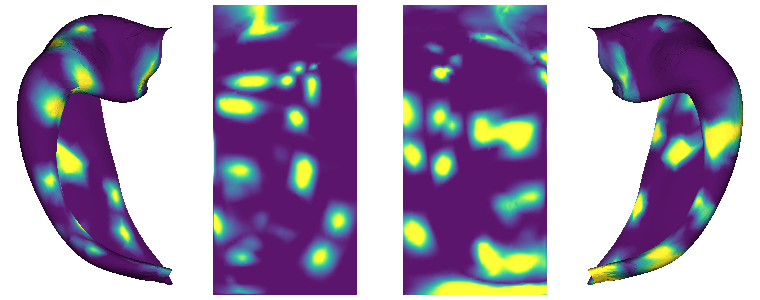

: 

In [ ]:
# Visualize hippocampus model correlations
from config import DATA_DIR

# 1. Input paths
hippunfold_dir = "/Volumes/Aiolo/deep-fMRI-dataset/derivatives/HippUnfold"
subjects = ["UTS03"]
            #,"UTS02","UTS03","UTS05","UTS06","UTS07","UTS08"]
den = "0p5mm" 
model = "whisper-large"
feature_space = "joint"

# 2. Resample 3D volume onto left and right hippocampal surfaces using trilinear interpolation
hemis = ["L", "R"]
labels = ["hipp"]

for sub in subjects:
    hemi_data = []
    for hemi in hemis:
        # Path to subject-specific midthickness surface in canonical density
        surf_path = Path(
            hippunfold_dir,
            f"sub-{sub}",
            "surf",
            f"sub-{sub}_hemi-{hemi}_space-T1w_den-{den}_label-hipp_midthickness.surf.gii"
        )

        mask_path = Path(DATA_DIR, "derivatives", "pycortex-db", sub, "transforms", f"{sub}_auto", "mask_thick.nii.gz")
        mask_img = nib.load(mask_path)
        mask_data = mask_img.get_fdata()
        corr_path = corr_nii_path = Path(DATA_DIR, "derivatives", "results", model, feature_space, sub, "corrs.npz")
        good_voxels_path = Path(DATA_DIR, "derivatives", "results", model, feature_space, sub, "good_voxels.npy")
        good_voxels = np.load(good_voxels_path)

        volume = np.zeros(mask_data.shape, dtype=np.float32)
        with np.load(corr_path) as corr_file:
            corr_values = corr_file["corrs"]

        mask = mask_data > 0
        volume[mask] = corr_values
        
        # Filter by voxels in "good_voxels"
        if good_voxels.size != corr_values.size:
            raise ValueError(
            f"Mask lengths differ: good_voxels={good_voxels.size}, "
            f"corr_values={corr_values.size}"
            )

        volume[mask] = np.where(good_voxels, corr_values, 0)

        corr_img = nib.Nifti1Image(
        volume,
            affine=mask_img.affine,
            header=mask_img.header
        )
        
        corr_nii_path = Path(DATA_DIR, "derivatives", "results", model, feature_space, sub, "corrs.nii.gz")
        nib.save(corr_img, corr_nii_path)

        # Trilinear volumetric-to-surface mapping along surface normal vectors
        corrs_surf = vol_to_surf(
            img=corr_nii_path,
            surf_mesh=surf_path,
            radius=1.0,
            interpolation="linear",  # Trilinear interpolation
            kind="line",
            n_samples=5,
        )
        
        # Replace any out-of-brain sampling NaNs with zeros or NaN
        corrs_surf = np.nan_to_num(corrs_surf, nan=0.0)
        hemi_data.append(corrs_surf)

    # 3. Stack into the exact shape expected by HippoMaps: (V, 2, F)
        # V = number of vertices (e.g., 7262 for den='0.5mm')
        # 2 = [Left, Right]
        # F = 1 feature column (correlation values)
    cdata = np.stack(hemi_data, axis=1)  # Shape: (V, 2)
    cdata = cdata[:, :, np.newaxis]       # Shape: (V, 2, 1)
    print(pd.Series(cdata.flatten()).describe())
    print(f"HippoMaps cdata array shape: {cdata.shape}")

    # Optional: Save array for fast reuse without re-sampling
    out_npy_path = Path(DATA_DIR, "derivatives", "results", model, feature_space, sub, "corrs_hippomaps.npy")
    np.save(out_npy_path, cdata)
    print(f"Saved surface correlation array to: {out_npy_path}")

    # 4. Render canonical folded and unfolded views inline, with a color bar for this subject
    from IPython.display import display, Markdown
    display(Markdown(f"### Subject {sub}"))
    display(hm.plotting.surfplot_canonical_foldunfold(
        cdata=cdata,
        den=den,
        hemis=hemis,
        labels=labels,
        cmap="viridis",
        tighten_cwindow=True,
        unfoldAPrescale=True,
        color_bar="right",
        embed_nb=True,
        interactive=False,
    ))


In [ ]:
# Nilearn plotting alternative 

view = plotting.view_surf(
        surf_mesh=Path(
            hippunfold_dir,
            f"sub-{sub}",
            "surf",
            f"sub-{sub}_hemi-L_space-T1w_den-{den}_label-hipp_midthickness.surf.gii"
        ),
        surf_map=cdata[:, 0, 0],  # Left hemisphere correlation values
        cmap="RdBu_r",
        symmetric_cmap=True,
    )

view.open_in_browser()

Average map shape: (7262, 2, 1)
Max correlation: 0.5952034534266711
Min correlation: -0.1273889094871444
Average correlation: 0.039979786581123146


### Average correlation across subjects

/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/.venv/lib/python3.11/site-packages/brainspace/plotting/surface_plotting.py:464: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(


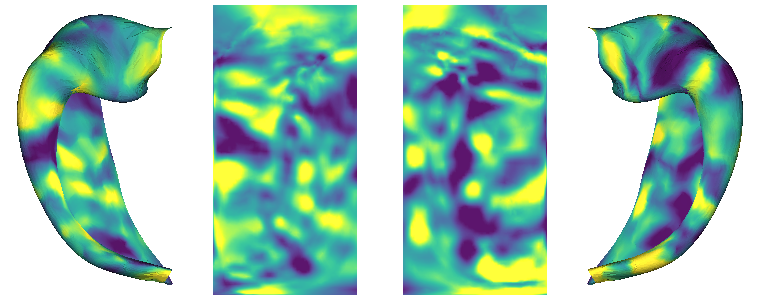

In [ ]:
# Average hippocampal encoding maps across participants
from IPython.display import display, Markdown

subjects = ["UTS01","UTS02","UTS03","UTS05","UTS06","UTS07","UTS08"]
model = "whisper-large"
feature_space = "joint"

subject_maps = []
for sub in subjects:
    hm_corr_path = Path(DATA_DIR, "derivatives", "results", model, feature_space, sub, "corrs_hippomaps.npy")
    hm_corr_values = np.load(hm_corr_path)
    subject_maps.append(hm_corr_values)

subject_maps = np.stack(subject_maps, axis=0)
total_avg = np.mean(subject_maps, axis=0)
total_avg_out_path = Path(DATA_DIR, "derivatives", "results", model, feature_space, "avg_corrs_hippomaps.npy")
# Save average correlation map as a NIfTI file 
nib.save(nib.Nifti1Image(total_avg, affine=np.eye(4)), total_avg_out_path)

display(Markdown("### Average correlation across subjects"))
display(hm.plotting.surfplot_canonical_foldunfold(
    cdata=total_avg,
    den=den,
    hemis=hemis,
    labels=labels,
    cmap="viridis",
    tighten_cwindow=True,
    unfoldAPrescale=True,
    color_bar="right",
    embed_nb=True,
    interactive=False,
))

Average map shape: (7262, 2, 1)
Max correlation: 0.5952034534266711
Min correlation: -0.1273889094871444
Average correlation: 0.039979786581123146


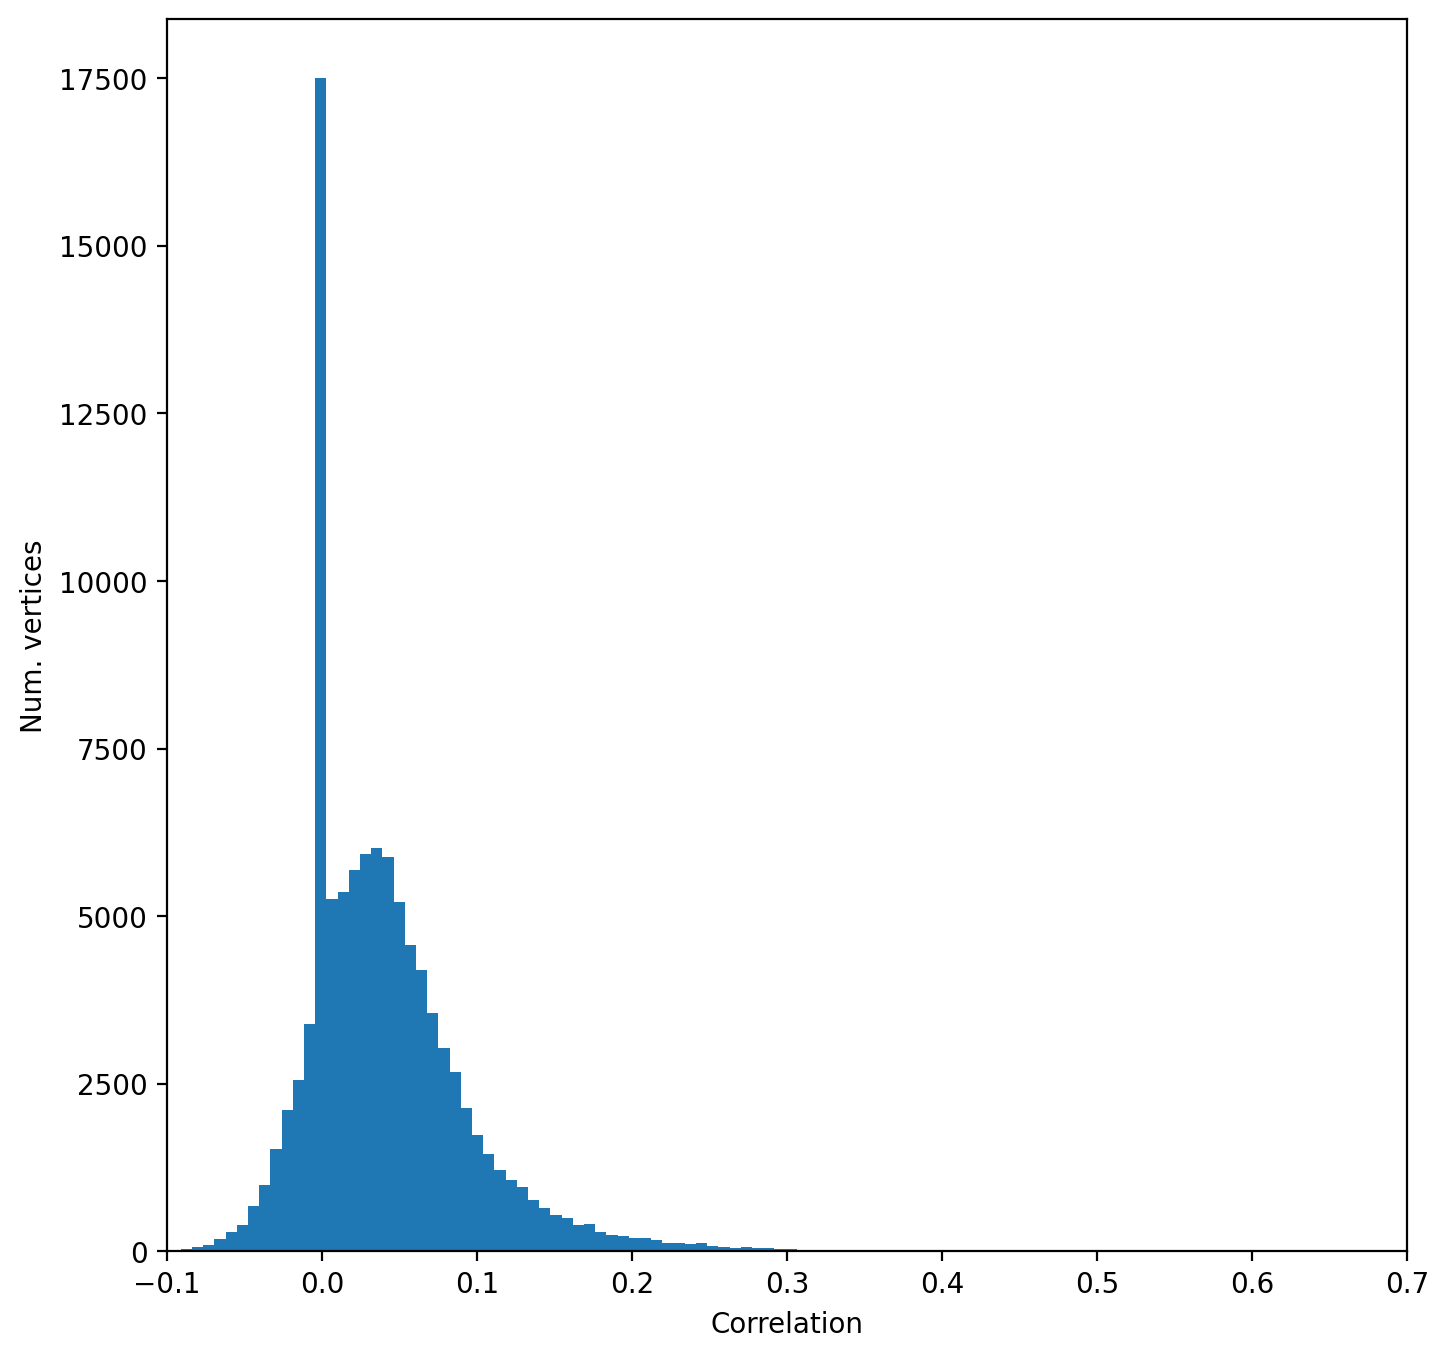

In [27]:
# Plot histogram of average correlation values across subjects
f = plt.figure(figsize=(8, 8))
ax = f.add_subplot(1, 1, 1)
ax.hist(subject_maps.flatten(), bins=100)
# Set max x and y limits for better visualization
ax.set_xlim(-0.1, 0.7)

ax.set_xlabel("Correlation")
ax.set_ylabel("Num. vertices")  

# Display max, min, and average correlation value
max_val = np.max(subject_maps)
min_val = np.min(subject_maps)
avg_val = np.mean(subject_maps)

print(f"Average map shape: {total_avg.shape}")
print(f"Max correlation: {max_val}")
print(f"Min correlation: {min_val}")
print(f"Average correlation: {avg_val}")

Significance testing and noise ceiling calculation

In [29]:
# Determine whether correlation values differ across hippocampal subfields and the long-axis gradient

subjects = ["UTS01"]
            #,"UTS02","UTS03","UTS05","UTS06","UTS07","UTS08"]

# Load subfield segmentation
for sub in subjects:
    subfield_path = Path(hippunfold_dir, f"sub-{sub}", "surf", f"sub-{sub}_space-T1w_den-0p5mm_label-hipp_atlas-bigbrain_subfields.dlabel.nii")
    cifti = nib.load(subfield_path)
    subfield_data = cifti.get_fdata(dtype=np.float32)


In [37]:
brain_model_axis = cifti.header.matrix.get_axis(1)

# List all structures present in the file (e.g., Left Cortex, Thalamus, etc.)
print("Structures in this CIFTI:")
print(brain_model_axis.name)

# Iterate through the structures to find their specific indices and vertices
for name, source_extent, mapping in brain_model_axis.iter_structures():
    print(f"\nStructure: {name}")
    print(f"  - Vector indices range: {source_extent}")

    print(f"  - Number of surface vertices: {len(mapping.vertex)}")

Structures in this CIFTI:
['CIFTI_STRUCTURE_CORTEX_LEFT' 'CIFTI_STRUCTURE_CORTEX_LEFT'
 'CIFTI_STRUCTURE_CORTEX_LEFT' ... 'CIFTI_STRUCTURE_CORTEX_RIGHT'
 'CIFTI_STRUCTURE_CORTEX_RIGHT' 'CIFTI_STRUCTURE_CORTEX_RIGHT']

Structure: CIFTI_STRUCTURE_CORTEX_LEFT
  - Vector indices range: slice(0, 7262, None)
  - Number of surface vertices: 7262

Structure: CIFTI_STRUCTURE_CORTEX_RIGHT
  - Vector indices range: slice(7262, None, None)
  - Number of surface vertices: 7262


In [ ]:
# Analyze long axis distribution

# For each subject, load AP Laplacian gradient and corrs file

# Ensure that these are aligned

# For 20ish steps from the start of the Laplacian, find the average correlation value

In [ ]:
hemis = ["L", "R"]

reg_space = 'individual'
hipp_surface = 'midthickness'

grid_shape = (126, 48)
num_grid_vertices = 12648
num_long_bins = 18
bin_edges = np.linspace(0, grid_shape[0], num_long_bins+1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0
long_axis_data = {
    h: [] for h in hemis
    }

total_avg = np.load(Path(DATA_DIR, "derivatives", "results", model, feature_space, "avg_corrs_hippomaps.npy"))

# Downsample long axis
binned_counts = np.array([
    np.sum(long_axis_counts[int(bin_edges[i]) : int(bin_edges[i+1])]) for i in range(num_long_bins)
    ]
)
long_axis_data[h].append(binned_counts)

fig, axes = plt.subplots(
    nrows=2, ncols=3, figsize=(15,8), sharex=True, sharey=True
)

for h in enumerate(hemis):
    ax = axes[h]

    subject_matrix = np.vstack(long_axis_data[h])

    mean_profile = np.mean(subject_matrix, axis=0)
    sem_profile = np.std(subject_matrix, axis=0) / np.sqrt(len(subjects))

    ax.plot(
        bin_centers,
        mean_profile,
        color="blue",
        linewidth=2.5,
        marker="o",
        label="Mean",
    )

    ax.fill_between(
        bin_centers,
        mean_profile - sem_profile,
        mean_profile + sem_profile,
        color="blue",
        alpha=0.25,
        label="+- SEM",
    )

    ax. set_title(f"{h}", fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.5)

    ax.set_xlabel("Long axis position (anterior -> posterior)")
    ax.set_ylabel("Vertex count")

axes[0,0].legend(loc="upper right")

plt.tight_layout()
plt.show()

### Variance partioning

/Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/encoding
Loading model correlations...
Cortical Voxel Summary (threshold r >= 0.05):
  Significant Voxels: 43,454 / 81,126
  Acoustic Winner: 20,041 voxels (46.1%)
  Speech   Winner: 15,154 voxels (34.9%)
  Language Winner: 8,259 voxels (19.0%)

Launching Pycortex cortical volume viewer...
Started server on port 8889
Open the viewer at http://localhost:8889/mixer.html (from another machine: http://Ians-MacBook-Pro-2.local:8889/mixer.html)



Reconstructing 3D NIfTI volumes for hippocampal projection...
Projecting continuous feature volumes onto hippocampal surfaces...
Rendering canonical folded and unfolded hippocampal maps...


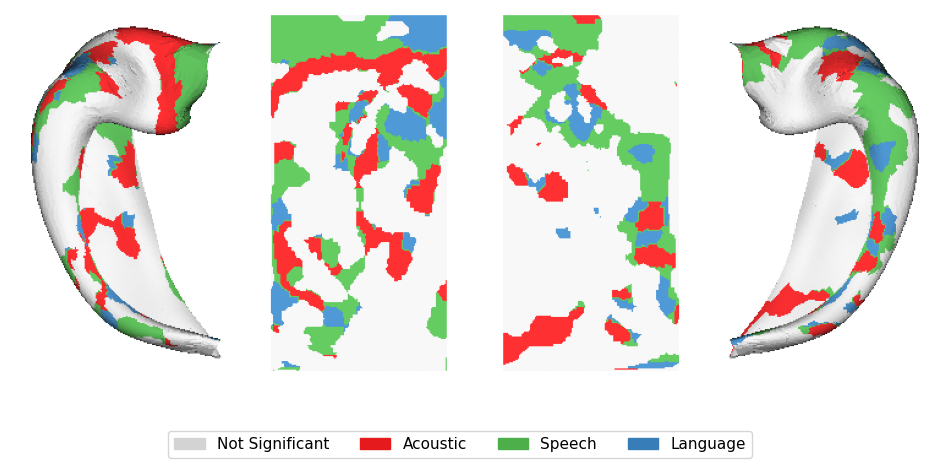

Saved corrected hippocampal winner map to: /Volumes/Aiolo/deep-fMRI-dataset/derivatives/results/whisper-large/UTS01_hippocampal_feature_winners.png


In [ ]:
%cd /Users/ianfaul/Code/HippEncoding/deep-fMRI-dataset/encoding
from variance_partitioning import partition_variance

partition_variance('UTS01','whisper-large',0.05)

In [ ]:
# Visualize cortex

# Set pycortex database directory
cortex.database.default_filestore = '/Volumes/Aiolo/deep-fMRI-dataset/derivatives/pycortex-db'

corrs_path = '/Volumes/Aiolo/deep-fMRI-dataset/derivatives/results/whisper-large/joint/UTS03/corrs.npz'

# 1. Load the 1D correlation array 
with np.load(corrs_path) as f:
    corr_values = f["corrs"]

# Ensure 1D shape
corr_values = np.squeeze(corr_values)

# 2. Pass the 1D array directly to cortex.Volume
# Pycortex automatically pairs the 1D array with UTS01_auto's mask_thick
weightvol = cortex.Volume(
    corr_values,
    subject="UTS03",
    xfmname="UTS03_auto",
    mask="thick",
    vmin=0.1,
    vmax=0.6,
    cmap="hot"
)

# 3. Launch interactive surface viewer
cortex.webshow(weightvol, port=8889, open_browser=False)

Started server on port 8889
Open the viewer at http://localhost:8889/mixer.html (from another machine: http://Ians-MacBook-Pro-2.local:8889/mixer.html)


DEBUG:asyncio:Using selector: KqueueSelector


<WebApp(Thread-4, started 17817432064)>

INFO:tornado.access:200 GET /mixer.html (::1) 44.12ms
INFO:tornado.access:200 GET /mixer.html (::1) 44.12ms
INFO:tornado.access:200 GET /resources/css/w2ui-1.4.2.min.css (::1) 25.00ms
INFO:tornado.access:200 GET /resources/css/w2ui-1.4.2.min.css (::1) 25.00ms
INFO:tornado.access:200 GET /resources/css/select2-4.0.3.min.css (::1) 6.29ms
INFO:tornado.access:200 GET /resources/css/select2-4.0.3.min.css (::1) 6.29ms
INFO:tornado.access:200 GET /resources/js/movement.js (::1) 13.11ms
INFO:tornado.access:200 GET /resources/js/movement.js (::1) 13.11ms
INFO:tornado.access:200 GET /resources/js/axes3d.js (::1) 16.11ms
INFO:tornado.access:200 GET /resources/js/axes3d.js (::1) 16.11ms
INFO:tornado.access:200 GET /resources/js/interpolation.js (::1) 22.32ms
INFO:tornado.access:200 GET /resources/js/interpolation.js (::1) 22.32ms
INFO:tornado.access:200 GET /resources/js/viewtools.js (::1) 30.12ms
INFO:tornado.access:200 GET /resources/js/viewtools.js (::1) 30.12ms
INFO:tornado.access:200 GET /res

Stopping server
